# 16 · Humidification and cooling towers

Every large plant rejects heat to the atmosphere through a cooling tower: warm water trickles down packing
against rising air, and a small fraction evaporates, cooling the rest. The process is simultaneous heat and
mass transfer, and Merkel's method reduces it to one integral in enthalpy - the same transfer-unit form as
absorption. This notebook computes the enthalpy driving force, the number of transfer units of a tower, the
approach to wet-bulb, and the water lost to evaporation.

**What you will learn**
- use enthalpy as the driving force for simultaneous heat and mass transfer
- compute Merkel's integral for a cooling tower
- relate approach, L/G and transfer units
- estimate evaporation, blowdown and make-up

**Before you start:** notebook 15  ·  **Time:** about 45 min

In [1]:
try:                      # on Google Colab (or anywhere engsep is missing): install it from GitHub
    import engsep
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engsep"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from engsep import drying_evaporation as de
from scipy import integrate
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## Enthalpy of saturated air: the equilibrium curve

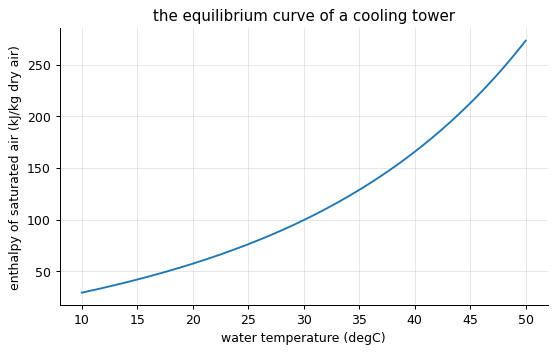

ambient air at 30.0 degC, 40% RH: enthalpy 57.9 kJ/kg, wet-bulb 20.3 degC


In [2]:
T = np.linspace(10, 50, 200)
H_sat = de.enthalpy_moist_air(T, de.humidity_saturation(T)) / 1e3
plt.plot(T, H_sat); plt.xlabel("water temperature (degC)"); plt.ylabel("enthalpy of saturated air (kJ/kg dry air)"); plt.title("the equilibrium curve of a cooling tower"); plt.show()
T_air, RH = 30.0, 0.4
H_in = de.enthalpy_moist_air(T_air, RH * de.humidity_saturation(T_air)) / 1e3
print(f"ambient air at {T_air} degC, {RH:.0%} RH: enthalpy {H_in:.1f} kJ/kg, wet-bulb {de.wet_bulb_temperature(T_air, RH * de.humidity_saturation(T_air)):.1f} degC")

The driving force for cooling is the difference between the enthalpy of air saturated at the water
temperature and the enthalpy of the bulk air - Merkel's insight that heat and mass transfer combine into an
enthalpy difference. The saturation curve rises steeply, so warm water has a large driving force and cold
water almost none: no tower cools below the ambient wet-bulb temperature.

## Merkel's integral: the tower's NTU

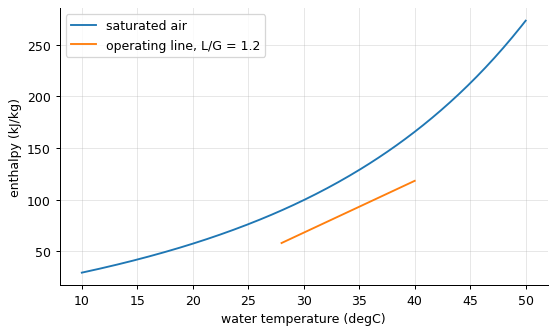

cooling from 40.0 to 28.0 degC (approach 7.7 K to wet-bulb): NTU = KaV/L = 1.42


In [3]:
T_hot, T_cold = 40.0, 28.0                                           # water in and out
L_over_G = 1.2                                                       # kg water per kg dry air
def air_enthalpy(Tw):                                                # operating line: H = H_in + (L/G) cp_w (T_w - T_cold)
    return H_in + L_over_G * 4.186 * (Tw - T_cold)
def integrand(Tw):
    return 4.186 / (de.enthalpy_moist_air(Tw, de.humidity_saturation(Tw)) / 1e3 - air_enthalpy(Tw))
NTU, _ = integrate.quad(integrand, T_cold, T_hot)
Tw = np.linspace(T_cold, T_hot, 100)
plt.plot(T, H_sat, label="saturated air"); plt.plot(Tw, air_enthalpy(Tw), label=f"operating line, L/G = {L_over_G}"); plt.xlabel("water temperature (degC)"); plt.ylabel("enthalpy (kJ/kg)"); plt.legend(); plt.show()
print(f"cooling from {T_hot} to {T_cold} degC (approach {T_cold - de.wet_bulb_temperature(T_air, RH * de.humidity_saturation(T_air)):.1f} K to wet-bulb): NTU = KaV/L = {NTU:.2f}")

The operating line is a straight line in the enthalpy-temperature plane (an energy balance), the equilibrium
curve the saturated-air enthalpy, and the tower's demand $KaV/L = \int c_p\,dT/(H^* - H)$ is the area between
them in reciprocal form. A packing's characteristic $KaV/L$ is measured by the manufacturer as a function
of L/G; matching demand to characteristic sizes the tower.

## The approach and the cost of cold water

In [4]:
T_wb = de.wet_bulb_temperature(T_air, RH * de.humidity_saturation(T_air))
for T_cold_ in (32.0, 28.0, 25.0, 23.0):
    if T_cold_ <= T_wb + 0.5:
        print(f"cold water at {T_cold_} degC: approach below 0.5 K - not achievable")
        continue
    H_in_ = H_in
    f = lambda Tw, Tc=T_cold_: 4.186 / (de.enthalpy_moist_air(Tw, de.humidity_saturation(Tw)) / 1e3 - (H_in_ + L_over_G * 4.186 * (Tw - Tc)))
    ntu_, _ = integrate.quad(f, T_cold_, T_hot)
    print(f"cold water at {T_cold_} degC (approach {T_cold_ - T_wb:.1f} K): NTU = {ntu_:.2f}")

cold water at 32.0 degC (approach 11.7 K): NTU = 0.58
cold water at 28.0 degC (approach 7.7 K): NTU = 1.42
cold water at 25.0 degC (approach 4.7 K): NTU = 3.23
cold water at 23.0 degC (approach 2.7 K): NTU = 8.07


The approach - how close the cold water gets to the wet-bulb temperature - is the tower's figure of merit,
and the transfer units needed grow without bound as it shrinks: a 3 K approach costs three times the packing
of an 8 K approach. Designers accept 5-8 K, and the wet-bulb temperature of the hottest summer week, not the
average, sets the design.

## Water lost: evaporation, drift and blowdown

In [5]:
H_out = air_enthalpy(T_hot) * 1e3
# the outlet air is nearly saturated at a temperature such that its enthalpy equals H_out
from scipy import optimize
T_out = optimize.brentq(lambda t: de.enthalpy_moist_air(t, de.humidity_saturation(t)) - H_out, 10.0, 60.0)
dH = de.humidity_saturation(T_out) - RH * de.humidity_saturation(T_air)
evap = dH / L_over_G                                                  # kg water evaporated per kg of circulating water
print(f"air leaves saturated at about {T_out:.1f} degC; evaporation {evap:.1%} of the circulating water; latent heat {evap * de.latent_heat(T_out)/1e3:.0f} kJ/kg of water vs sensible cooling {4.186 * (T_hot - T_cold):.0f} kJ/kg")
cycles = 4
print(f"at {cycles} cycles of concentration the blowdown is {evap/(cycles-1):.1%} and the make-up {evap * cycles/(cycles-1):.1%} of the circulation")

air leaves saturated at about 33.3 degC; evaporation 1.8% of the circulating water; latent heat 45 kJ/kg of water vs sensible cooling 50 kJ/kg
at 4 cycles of concentration the blowdown is 0.6% and the make-up 2.5% of the circulation


About 80 % of the cooling is latent heat: each kilogram of water cooled by 12 K loses 2 % of itself to the
air. The dissolved solids stay behind, so a bleed (blowdown) keeps them from scaling the packing; the make-up
water is evaporation plus blowdown, and its treatment is the operating cost of an otherwise free heat sink.

## Inside the algorithm: Merkel's integrand

In [6]:
Tw_ = 34.0
print("by hand at 34 degC: 1/(H* - H) =", 1 / (de.enthalpy_moist_air(Tw_, de.humidity_saturation(Tw_)) / 1e3 - air_enthalpy(Tw_)), "kg/kJ")

by hand at 34 degC: 1/(H* - H) = 0.02914412758525741 kg/kJ


## Exercises
1. Repeat the tower calculation for a humid summer day (34 degC, 70 % RH). What cold-water temperature can the same tower (same NTU) now reach, and by how much must the water rate drop (lower L/G) to hold 28 degC?
2. A counterflow tower has a packing characteristic KaV/L = 1.8 (L/G)^-0.6. Find the L/G at which it exactly meets the demand for cooling 40 -> 28 degC at 30 degC / 40 % RH, and the corresponding air flow per kg of water.
3. **Implement it yourself:** evaluate Merkel's integral with Simpson's rule on ten intervals and compare with quad.